# Modularity on the Karate Club Graph
**DSC212 – Graph Theory | Research Assignment**

**Name:** Kamalanad R **RollNo:** IMS25106

This notebook implements recursive spectral modularity partitioning (Newman, 2006, *PNAS* 103(23):8577–8582) from scratch, visualises each split, tracks four node metrics across iterations, and then goes further: ground-truth validation, comparison with other algorithms, robustness under edge noise, a random-graph null model, a planted-partition phase transition, and a benchmark across several other networks.

**Contents**
1. Setup and the data
2. Modularity matrix and sanity checks
3. Recursive spectral bisection (two variants)
4. Visualisation after each split
5. Node metrics across iterations
6. Extra analysis: ground truth, spectrum, algorithm comparison, robustness, null model, SBM phase transition, other networks
7. Discussion

Runs top-to-bottom with `numpy`, `scipy`, `pandas`, `matplotlib`, `scikit-learn` and `networkx` only.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score as ARI, normalized_mutual_info_score as NMI

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
RNG = np.random.default_rng(0)

_G0 = nx.karate_club_graph()                    # NetworkX ships this WITH edge weights (sum = 231)
G = nx.Graph(); G.add_nodes_from(_G0.nodes(data=True)); G.add_edges_from(_G0.edges())   # unweighted, as in the handout: 78 edges
n, m = G.number_of_nodes(), G.number_of_edges()
club = np.array([G.nodes[i]["club"] for i in range(n)])
truth = (club == "Officer").astype(int)         # 0 = Mr. Hi, 1 = Officer (president)
print(f"n = {n}, m = {m}")
print("Ground-truth faction sizes:", dict(zip(*np.unique(club, return_counts=True))))

n = 34, m = 78
Ground-truth faction sizes: {np.str_('Mr. Hi'): np.int64(17), np.str_('Officer'): np.int64(17)}


## 2. Modularity matrix and sanity checks
$B = A - \frac{kk^\top}{2m}$. We verify Proposition 1 (real symmetric), Proposition 2 ($B\mathbf 1 = 0$) and Corollary 1 ($Q(\mathbf 1)=0$) numerically.

In [ ]:
def modularity_matrix(G):
    nodes = sorted(G.nodes())
    A = nx.to_numpy_array(G, nodelist=nodes)
    k = A.sum(axis=1)
    m = k.sum() / 2
    B = A - np.outer(k, k) / (2 * m)
    return B, A, k, m, nodes

B, A, k, m_, nodes = modularity_matrix(G)
print("B symmetric:           ", np.allclose(B, B.T))
print("||B·1||_inf  (≈ 0):    ", np.abs(B @ np.ones(n)).max())
print("Q(s = 1)  (= 0):       ", np.ones(n) @ B @ np.ones(n) / (4 * m_))
w = np.linalg.eigvalsh(B)[::-1]
print("Largest eigenvalues of B:", np.round(w[:4], 4))

B symmetric:            True
||B·1||_inf  (≈ 0):     8.881784197001252e-16
Q(s = 1)  (= 0):        1.120898246015783e-17
Largest eigenvalues of B: [4.9771 3.0428 2.3202 1.4888]


## 3. Recursive spectral bisection

Two variants are implemented, because the handout's rule has a subtlety worth testing.

* **`assignment`** – exactly as written in the handout: take the sub-block $B^{(C)}$ of the global $B$, split by the sign of its leading eigenvector, stop when $\lambda_1^{(C)}\le 0$.
* **`newman`** – Newman's *generalised* matrix $B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in g}B_{il}$. The extra diagonal term makes $B^{(g)}\mathbf 1=0$ and makes $\tfrac1{4m}s^\top B^{(g)}s$ the **exact** change in $Q$. With the plain block, $\tfrac1{4m}s^\top B^{(C)}s$ omits the interaction of $C$ with the rest of the graph and is only an approximation of $\Delta Q$.

* **`newman+dq`** – as `newman`, but a split is also rejected if its exact $\Delta Q\le 0$. This is Newman's actual acceptance rule: $\lambda_1>0$ guarantees only that *some* real vector has $s^\top B s>0$, not that the sign-rounded $\pm1$ vector does.

At every split we record the true global modularity $Q$ (via `networkx`) so we can check the claim "each accepted split increases $Q$".

In [ ]:
def spectral_modularity_partition(G, mode="assignment", tol=1e-9):
    # Recursive bisection. Returns (history, finals).
    # history[t] : state after t accepted splits (t = 0 is the whole graph)
    # finals     : (size, lambda_1) of each community when it was declared indivisible
    B, A, k, m, nodes = modularity_matrix(G)
    N = len(nodes)
    comms = [{"idx": list(range(N)), "open": True}]

    def labels_of(cs):
        lab = np.empty(N, int)
        for c, d in enumerate(cs): lab[d["idx"]] = c
        return lab
    def Q_of(cs):
        return nx.community.modularity(G, [{nodes[i] for i in d["idx"]} for d in cs])

    history = [dict(step=0, labels=labels_of(comms), Q=Q_of(comms), lam=None, dQ=0.0, sizes=(N,), parent=None)]
    finals = []
    while any(d["open"] for d in comms):
        pos = next(i for i, d in enumerate(comms) if d["open"])
        C = comms[pos]["idx"]
        Bc = B[np.ix_(C, C)].copy()
        if mode.startswith("newman"):
            Bc -= np.diag(Bc.sum(axis=1))
        vals, vecs = np.linalg.eigh(Bc)             # ascending; B is symmetric (Thm 1)
        lam, u = vals[-1], vecs[:, -1]
        if lam <= tol:
            comms[pos]["open"] = False; finals.append((len(C), lam)); continue
        s = np.where(u > 0, 1, -1)                  # threshold: > 0 -> +1, otherwise -1
        if abs(s.sum()) == len(s):                  # degenerate: everyone on one side
            comms[pos]["open"] = False; finals.append((len(C), lam)); continue
        if mode == "newman+dq" and s @ Bc @ s / (4 * m) <= tol:     # lambda_1 > 0 is necessary, not sufficient
            comms[pos]["open"] = False; finals.append((len(C), lam)); continue
        Cp = [C[i] for i in range(len(C)) if s[i] > 0]
        Cm = [C[i] for i in range(len(C)) if s[i] < 0]
        Qold = Q_of(comms)
        comms[pos:pos+1] = [{"idx": Cp, "open": True}, {"idx": Cm, "open": True}]
        Qnew = Q_of(comms)
        history.append(dict(step=len(history), labels=labels_of(comms), Q=Qnew, lam=lam,
                            dQ=Qnew - Qold, dQ_formula=s @ Bc @ s / (4 * m),
                            sizes=(len(Cp), len(Cm)), parent=len(C)))
    return history, finals

H_asg, fin_asg = spectral_modularity_partition(G, "assignment")
H_nl, fin_nl = spectral_modularity_partition(G, "newman")        # lambda rule only
H_new, fin_new = spectral_modularity_partition(G, "newman+dq")   # + exact dQ > 0 check

def summarize(H, name):
    rows = [dict(step=h["step"], split=("—" if h["parent"] is None else f'{h["parent"]} → {h["sizes"][0]}+{h["sizes"][1]}'),
                 lambda1=h["lam"], dQ_true=h["dQ"], dQ_formula=h.get("dQ_formula", np.nan), Q=h["Q"],
                 n_comms=len(np.unique(h["labels"]))) for h in H]
    print(f"=== {name} ==="); print(pd.DataFrame(rows).round(4).to_string(index=False)); print()
summarize(H_asg, "assignment (plain restricted block)")
summarize(H_nl, "newman (generalised B^(g), lambda rule only)")
summarize(H_new, "newman+dq (generalised B^(g), lambda rule + dQ > 0)")
print("Indivisible communities (size, lambda_1):")
print("  assignment:", [(s, round(l, 3)) for s, l in fin_asg])
print("  newman    :", [(s, round(l, 3)) for s, l in fin_nl])
print("  newman+dq :", [(s, round(l, 3)) for s, l in fin_new])

=== assignment (plain restricted block) ===
 step      split  lambda1  dQ_true  dQ_formula      Q  n_comms
    0          —      NaN   0.0000         NaN 0.0000        1
    1 34 → 16+18   4.9771   0.3715      0.3715 0.3715        2
    2  16 → 10+6   2.9441   0.0183      0.1112 0.3898        3
    3    6 → 1+5   2.1480   0.0013      0.0338 0.3911        4
    4  18 → 5+13   2.5041   0.0183      0.1112 0.4094        5

=== newman (generalised B^(g), lambda rule only) ===
 step      split  lambda1  dQ_true  dQ_formula      Q  n_comms
    0          —      NaN   0.0000         NaN 0.0000        1
    1 34 → 16+18   4.9771   0.3715      0.3715 0.3715        2
    2   16 → 7+9   1.1785   0.0012      0.0012 0.3727        3
    3    9 → 4+5   0.0602  -0.0158     -0.0158 0.3569        4
    4  18 → 12+6   0.8594   0.0207      0.0207 0.3776        5

=== newman+dq (generalised B^(g), lambda rule + dQ > 0) ===
 step      split  lambda1  dQ_true  dQ_formula      Q  n_comms
    0          —      

**Reading the table.** `dQ_true` is the real change in global $Q$; `dQ_formula` is $\frac1{4m}s^\top B^{(C)}s$ using the matrix each variant uses. For the `newman` variant they agree to rounding error, i.e. Theorem 3's identity holds exactly. For the plain `assignment` block they differ once $C\neq V$ — that is the correction term above. (At the very first split $C=V$ and the two variants coincide.)

In [ ]:
# Which variant do we carry forward? Use the handout's method as primary, report the other in analysis.
H = H_asg
final_labels = H[-1]["labels"]
print("Primary (handout) partition: ", len(np.unique(final_labels)), "communities, Q =", round(H[-1]["Q"], 4))
print("Newman (B^(g) + dQ>0) partition:", len(np.unique(H_new[-1]["labels"])), "communities, Q =", round(H_new[-1]["Q"], 4))
print("Partitions identical (ARI):  ", round(ARI(H[-1]["labels"], H_new[-1]["labels"]), 4))

Primary (handout) partition:  5 communities, Q = 0.4094
Newman (B^(g) + dQ>0) partition: 4 communities, Q = 0.3934
Partitions identical (ARI):   0.8244


## 4. Visualisation after each split
Fixed spring layout (`seed=42`), one colour per community, nodes labelled by ID. The top-left panel is the starting graph; bottom-right (if present) is blank.

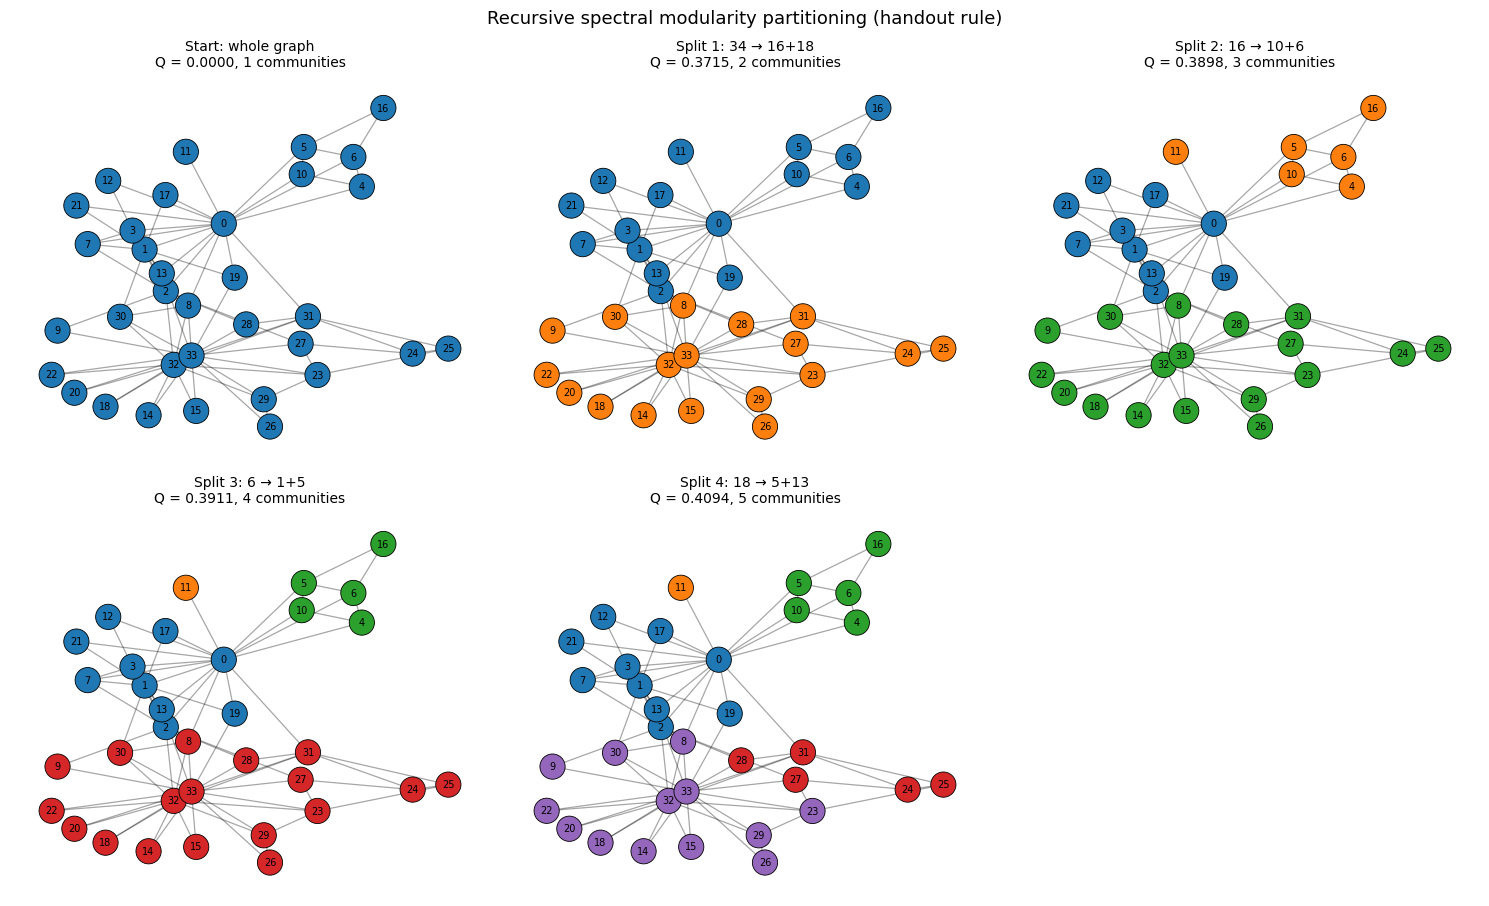

In [ ]:
pos = nx.spring_layout(G, seed=42)
cmap = plt.get_cmap("tab10")

def draw_partition(ax, labels, title):
    cols = [cmap(labels[i] % 10) for i in G.nodes()]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=.35, width=.9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=cols, node_size=330, edgecolors="k", linewidths=.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10); ax.axis("off")

def draw_history(H, name):
    T = len(H); ncol = 3; nrow = int(np.ceil(T / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4.6 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, h in zip(axes, H):
        t = "Start: whole graph" if h["step"] == 0 else f'Split {h["step"]}: {h["parent"]} → {h["sizes"][0]}+{h["sizes"][1]}'
        draw_partition(ax, h["labels"], f'{t}\nQ = {h["Q"]:.4f}, {len(np.unique(h["labels"]))} communities')
    for ax in axes[T:]: ax.axis("off")
    fig.suptitle(name, fontsize=13); fig.tight_layout(); plt.show()

draw_history(H, "Recursive spectral modularity partitioning (handout rule)")

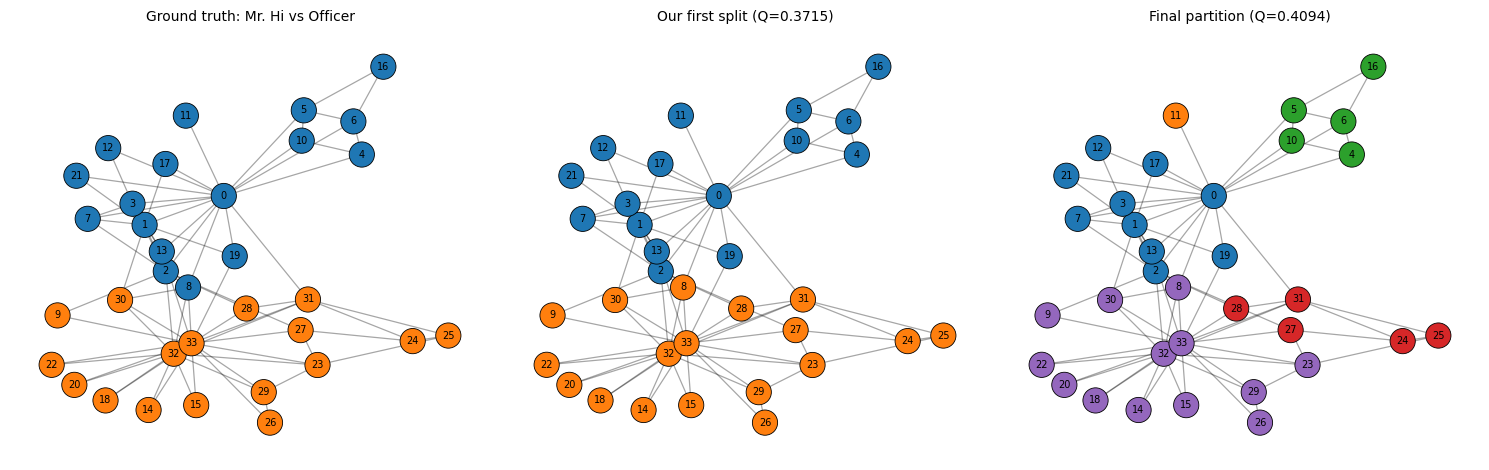

In [ ]:
# Ground-truth split alongside our first split and final partition
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
draw_partition(axes[0], truth, "Ground truth: Mr. Hi vs Officer")
draw_partition(axes[1], H[1]["labels"], f'Our first split (Q={H[1]["Q"]:.4f})')
draw_partition(axes[2], H[-1]["labels"], f'Final partition (Q={H[-1]["Q"]:.4f})')
plt.tight_layout(); plt.show()

## 5. Node metrics across iterations

If we computed centralities on the full graph $G$ they would never change between iterations. To see how the *community structure* affects them, after iteration $t$ we compute each metric on the graph $G_t$ that keeps **only the edges inside communities** (cross-community edges removed). Iteration 0 is the original graph. This is the quantity each node "feels" from within its own community.

Note on closeness: `networkx` uses the Wasserman–Faust scaling on disconnected graphs, so a node in a small component is penalised for the nodes it cannot reach.

In [ ]:
METRICS = {"degree": nx.degree_centrality, "betweenness": nx.betweenness_centrality,
           "closeness": nx.closeness_centrality, "clustering": nx.clustering}

def intra_graph(G, labels):
    Ht = nx.Graph(); Ht.add_nodes_from(G.nodes())
    Ht.add_edges_from((u, v) for u, v in G.edges() if labels[u] == labels[v])
    return Ht

def metric_history(G, H):
    store = {name: {} for name in METRICS}           # store[metric][iteration] = {node: value}
    for h in H:
        Ht = intra_graph(G, h["labels"])
        for name, f in METRICS.items():
            store[name][h["step"]] = f(Ht)
    return store

store = metric_history(G, H)
tables = {name: pd.DataFrame(store[name]).sort_index() for name in METRICS}   # rows = node, cols = iteration
for name in METRICS:
    print(f"--- {name}: top 5 at iteration 0 and at final iteration ---")
    print(pd.concat([tables[name][0].nlargest(5).rename("iter 0"),
                     tables[name][len(H)-1].nlargest(5).rename(f"iter {len(H)-1}")], axis=1).round(3).to_string()); print()

--- degree: top 5 at iteration 0 and at final iteration ---
    iter 0  iter 4
33   0.515   0.364
0    0.485   0.273
32   0.364   0.303
2    0.303     NaN
1    0.273   0.242
3      NaN   0.182

--- betweenness: top 5 at iteration 0 and at final iteration ---
    iter 0  iter 4
0    0.438   0.024
33   0.304   0.068
32   0.145   0.032
2    0.144     NaN
31   0.138     NaN
1      NaN   0.015
24     NaN   0.006

--- closeness: top 5 at iteration 0 and at final iteration ---
    iter 0  iter 4
0    0.569   0.273
2    0.559     NaN
33   0.550   0.364
31   0.541     NaN
8    0.516     NaN
32     NaN   0.312
1      NaN   0.245
29     NaN   0.218

--- clustering: top 5 at iteration 0 and at final iteration ---
    iter 0  iter 4
7      1.0     1.0
12     1.0     1.0
14     1.0     1.0
15     1.0     NaN
16     1.0     NaN
8      NaN     1.0
13     NaN     1.0



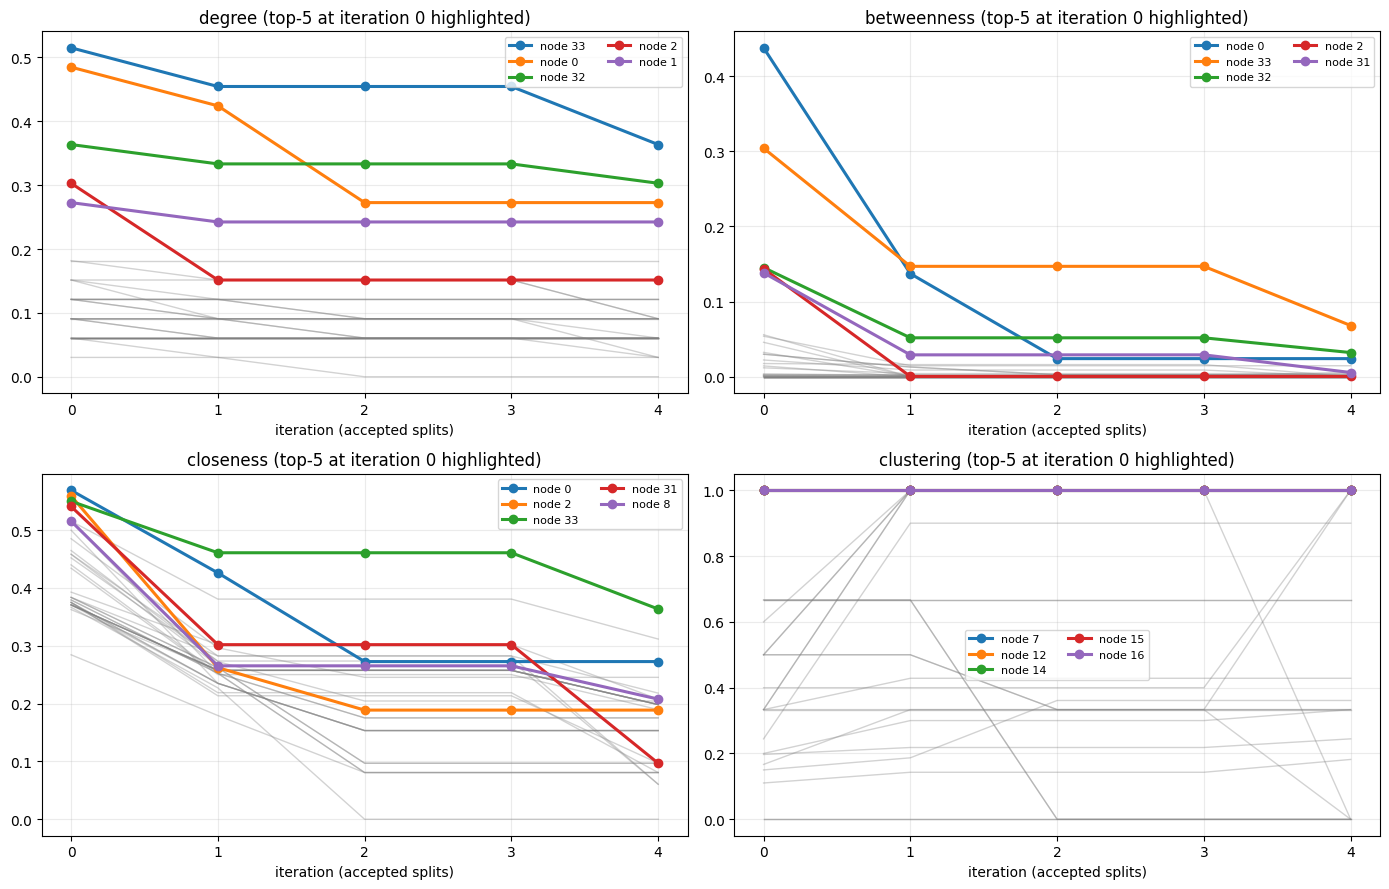

In [ ]:
# Evolution plots: every node as a faint line, the 5 most central nodes at iteration 0 highlighted
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
iters = list(range(len(H)))
for ax, name in zip(axes.ravel(), METRICS):
    T = tables[name]
    top = T[0].nlargest(5).index
    for node in T.index:
        if node not in top: ax.plot(iters, T.loc[node], color="grey", alpha=.35, lw=1)
    for j, node in enumerate(top):
        ax.plot(iters, T.loc[node], marker="o", lw=2.2, color=cmap(j), label=f"node {node}")
    ax.set_title(f"{name} (top-5 at iteration 0 highlighted)"); ax.set_xlabel("iteration (accepted splits)")
    ax.set_xticks(iters); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

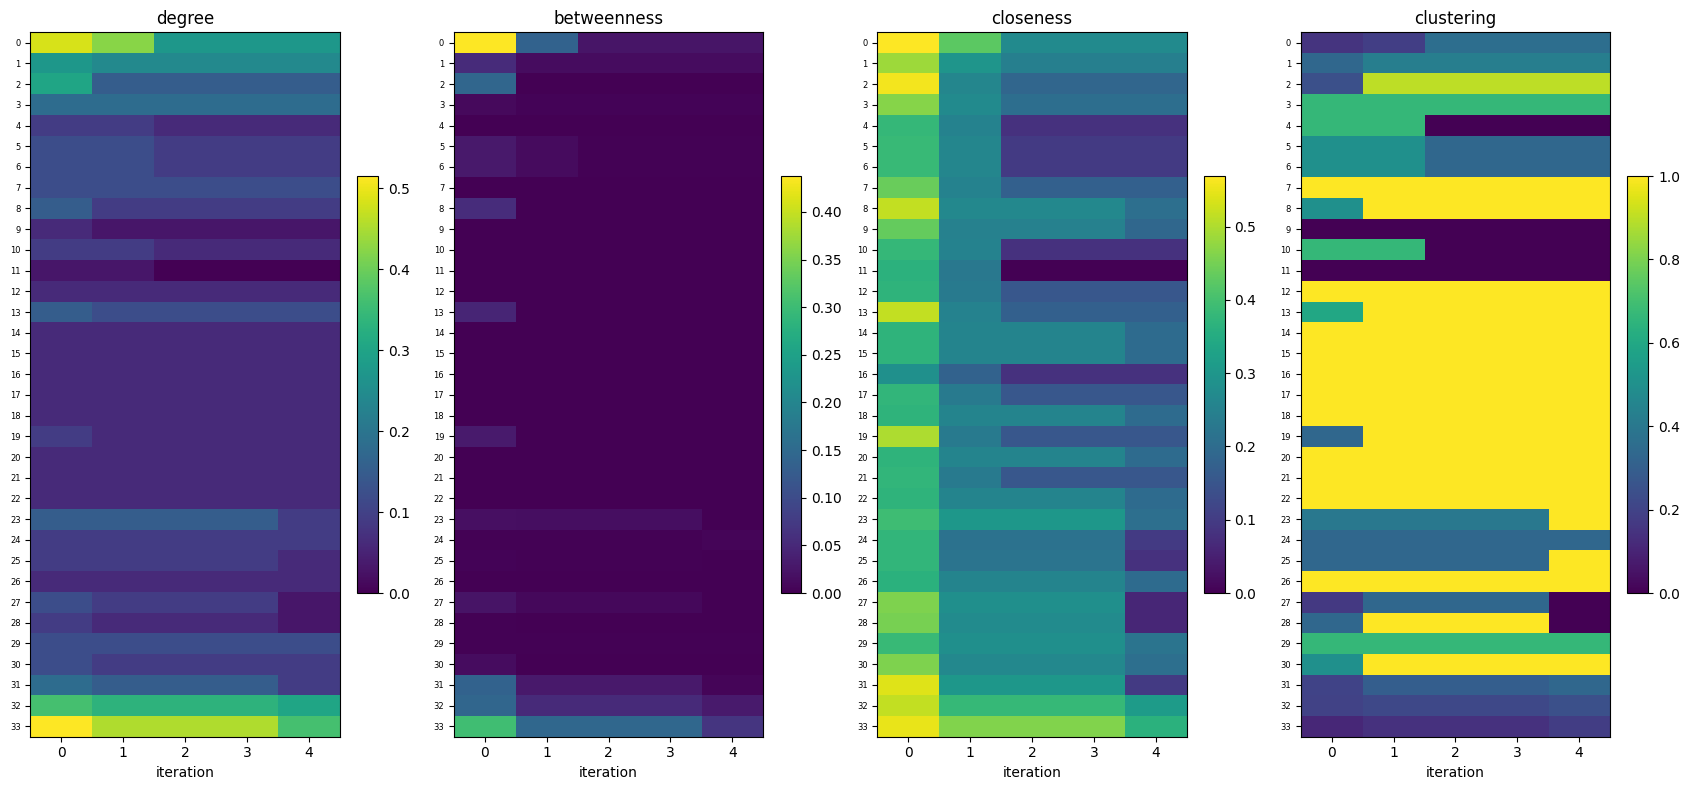

In [ ]:
# Complete per-node view: heatmaps (rows = nodes, columns = iterations)
fig, axes = plt.subplots(1, 4, figsize=(17, 8))
for ax, name in zip(axes, METRICS):
    T = tables[name]
    im = ax.imshow(T.values, aspect="auto", cmap="viridis")
    ax.set_title(name); ax.set_xlabel("iteration"); ax.set_xticks(iters)
    ax.set_yticks(range(n)); ax.set_yticklabels(T.index, fontsize=6); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=.06)
plt.tight_layout(); plt.show()

In [ ]:
# How consistently does a node stay in the top-5 for each metric across ALL iterations?
rows = {}
for name in METRICS:
    T = tables[name]
    count = pd.Series(0, index=T.index)
    for t in T.columns:
        count[T[t].nlargest(5).index] += 1
    rows[name] = count
top5 = pd.DataFrame(rows); top5["total"] = top5.sum(axis=1)
print(f"Number of iterations (out of {len(H)}) a node is in the top-5:")
print(top5.sort_values("total", ascending=False).head(10).to_string())

# Rank stability relative to iteration 0 (Spearman)
print("\nSpearman rank correlation of each metric with its iteration-0 values:")
print(pd.DataFrame({name: [tables[name][0].corr(tables[name][t], method="spearman") for t in tables[name].columns]
                    for name in METRICS}, index=[f"iter {t}" for t in iters]).round(3).to_string())

Number of iterations (out of 5) a node is in the top-5:
    degree  betweenness  closeness  clustering  total
33       5            5          5           0     15
32       5            5          4           0     14
0        5            5          3           0     13
31       0            4          4           0      8
1        5            1          1           0      7
23       0            3          3           0      6
8        0            0          1           4      5
7        0            0          0           5      5
14       0            0          0           5      5
12       0            0          0           5      5

Spearman rank correlation of each metric with its iteration-0 values:
        degree  betweenness  closeness  clustering
iter 0   1.000        1.000      1.000       1.000
iter 1   0.950        0.712      0.633       0.815
iter 2   0.941        0.706      0.397       0.688
iter 3   0.941        0.706      0.397       0.688
iter 4   0.842        0.

## 6. Extra analysis

### 6.1 Does the spectral split recover the real split of the club?

In [ ]:
rows = []
for h in H:
    lab = h["labels"]
    rows.append(dict(step=h["step"], n_comms=len(np.unique(lab)), Q=h["Q"], ARI_vs_truth=ARI(truth, lab), NMI_vs_truth=NMI(truth, lab)))
print(pd.DataFrame(rows).round(4).to_string(index=False))

lab1 = H[1]["labels"]
agree = (lab1 == truth).mean(); flip = (lab1 != truth).mean()
if flip > agree: lab1 = 1 - lab1                      # fix arbitrary sign of eigenvector
wrong = [i for i in range(n) if lab1[i] != truth[i]]
print(f"\nFirst split vs ground truth: accuracy = {(lab1 == truth).mean():.4f}; misclassified nodes = {wrong}")
for i in wrong:
    nb = list(G[i]); print(f"  node {i}: true club = {club[i]}, neighbours = {nb}, "
                           f"neighbours in Mr.Hi = {sum(truth[j]==0 for j in nb)}, in Officer = {sum(truth[j]==1 for j in nb)}")
print("\nContingency of final partition vs ground truth:")
print(pd.crosstab(pd.Series(club, name="true faction"), pd.Series(H[-1]["labels"], name="found community")).to_string())

 step  n_comms      Q  ARI_vs_truth  NMI_vs_truth
    0        1 0.0000        0.0000        0.0000
    1        2 0.3715        0.8823        0.8372
    2        3 0.3898        0.6660        0.6835
    3        4 0.3911        0.6479        0.6529
    4        5 0.4094        0.4463        0.5646

First split vs ground truth: accuracy = 0.9706; misclassified nodes = [8]
  node 8: true club = Mr. Hi, neighbours = [0, 2, 30, 32, 33], neighbours in Mr.Hi = 2, in Officer = 3

Contingency of final partition vs ground truth:
found community   0  1  2  3   4
true faction                    
Mr. Hi           10  1  5  0   1
Officer           0  0  0  5  12


### 6.2 Spectrum of $B$ and the leading eigenvector (soft assignment)

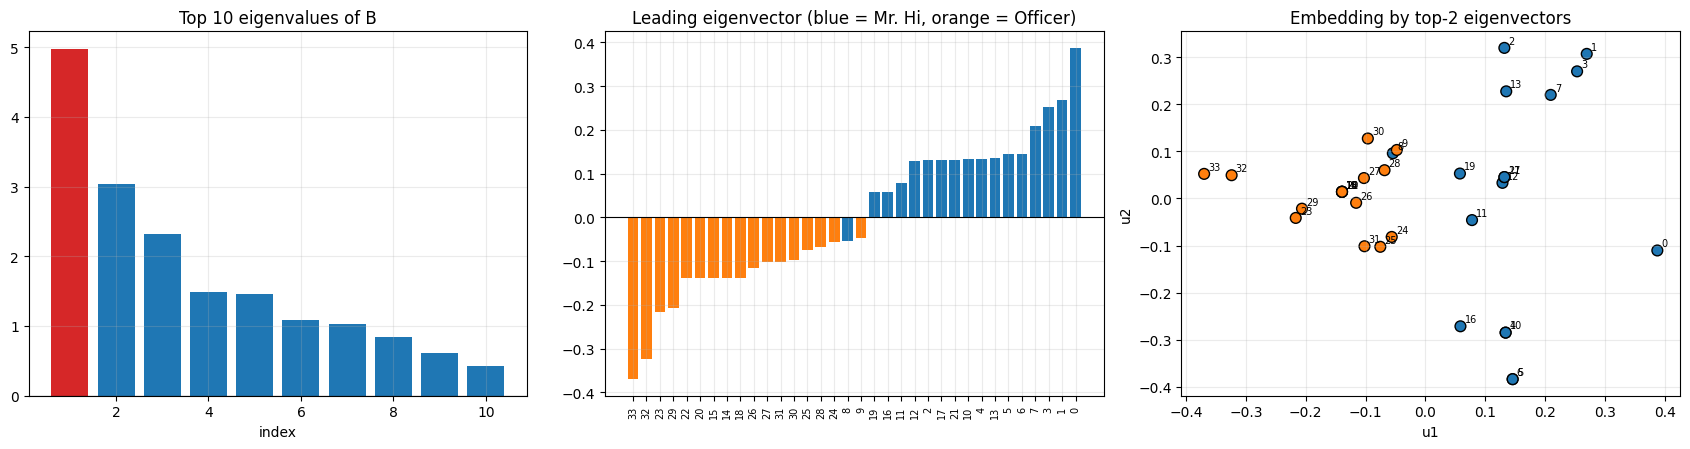

Nodes closest to the threshold (|u1| smallest) = least certain assignments:
9     0.0479
8     0.0545
24    0.0563
19    0.0576
16    0.0585
28    0.0683

Eigengap lambda1 - lambda2 = 1.934  (lambda1 = 4.977, lambda2 = 3.043)


In [ ]:
vals, vecs = np.linalg.eigh(B)
u1 = vecs[:, -1]
if (np.sign(u1) == (1 - 2 * truth)).mean() < .5: u1 = -u1     # orient: positive ~ Mr. Hi side
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].bar(range(1, 11), vals[::-1][:10], color=["C3"] + ["C0"] * 9)
axes[0].axhline(0, color="k", lw=.8); axes[0].set_title("Top 10 eigenvalues of B"); axes[0].set_xlabel("index")
order = np.argsort(u1)
axes[1].bar(range(n), u1[order], color=[("C0" if truth[i] == 0 else "C1") for i in order])
axes[1].set_xticks(range(n)); axes[1].set_xticklabels(order, fontsize=7, rotation=90)
axes[1].axhline(0, color="k", lw=.8); axes[1].set_title("Leading eigenvector (blue = Mr. Hi, orange = Officer)")
axes[2].scatter(vecs[:, -1], vecs[:, -2], c=[("C0" if t == 0 else "C1") for t in truth], s=60, edgecolors="k")
for i in range(n): axes[2].annotate(str(i), (vecs[i, -1], vecs[i, -2]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[2].set_xlabel("u1"); axes[2].set_ylabel("u2"); axes[2].set_title("Embedding by top-2 eigenvectors")
plt.tight_layout(); plt.show()
print("Nodes closest to the threshold (|u1| smallest) = least certain assignments:")
print(pd.Series(np.abs(u1), name="|u1|").nsmallest(6).round(4).to_string())
print(f"\nEigengap lambda1 - lambda2 = {vals[-1]-vals[-2]:.3f}  (lambda1 = {vals[-1]:.3f}, lambda2 = {vals[-2]:.3f})")

### 6.3 Comparison with other community-detection algorithms
The literature's best known modularity for this graph is $Q\approx0.4198$ (4 communities). We compare our methods to greedy agglomeration, Louvain, label propagation and Girvan–Newman.

In [ ]:
def Qof(parts): return nx.community.modularity(G, parts)
def lab_to_sets(lab): return [set(np.where(lab == c)[0]) for c in np.unique(lab)]
def sets_to_lab(parts):
    lab = np.empty(n, int)
    for c, s in enumerate(parts): lab[list(s)] = c
    return lab

res = {}
res["Spectral bisection, 1 split"] = H[1]["labels"]
res["Spectral recursive (handout)"] = H[-1]["labels"]
res["Spectral recursive (Newman B^(g)+dQ)"] = H_new[-1]["labels"]
res["Greedy modularity (CNM)"] = sets_to_lab(nx.community.greedy_modularity_communities(G))
louv = [sets_to_lab(nx.community.louvain_communities(G, seed=s)) for s in range(50)]
best = max(louv, key=lambda l: Qof(lab_to_sets(l)))
res["Louvain (best of 50 seeds)"] = best
res["Label propagation (seed 0)"] = sets_to_lab(nx.community.asyn_lpa_communities(G, seed=0))
gn = next(nx.community.girvan_newman(G)); res["Girvan–Newman (first split)"] = sets_to_lab(gn)
res["Ground truth (2 factions)"] = truth
cmp_df = pd.DataFrame([dict(method=k_, n_comms=len(np.unique(v)), Q=Qof(lab_to_sets(v)), ARI_vs_truth=ARI(truth, v), NMI_vs_truth=NMI(truth, v)) for k_, v in res.items()])
print(cmp_df.round(4).to_string(index=False))
print("\nLouvain across 50 seeds: Q range =", round(min(Qof(lab_to_sets(l)) for l in louv), 4), "to", round(max(Qof(lab_to_sets(l)) for l in louv), 4))

                              method  n_comms      Q  ARI_vs_truth  NMI_vs_truth
         Spectral bisection, 1 split        2 0.3715        0.8823        0.8372
        Spectral recursive (handout)        5 0.4094        0.4463        0.5646
Spectral recursive (Newman B^(g)+dQ)        4 0.3934        0.4352        0.5792
             Greedy modularity (CNM)        3 0.3807        0.5684        0.5646
          Louvain (best of 50 seeds)        4 0.4198        0.4646        0.5878
          Label propagation (seed 0)        3 0.4020        0.5906        0.5684
         Girvan–Newman (first split)        2 0.3600        0.7717        0.7324
           Ground truth (2 factions)        2 0.3582        1.0000        1.0000

Louvain across 50 seeds: Q range = 0.3854 to 0.4198


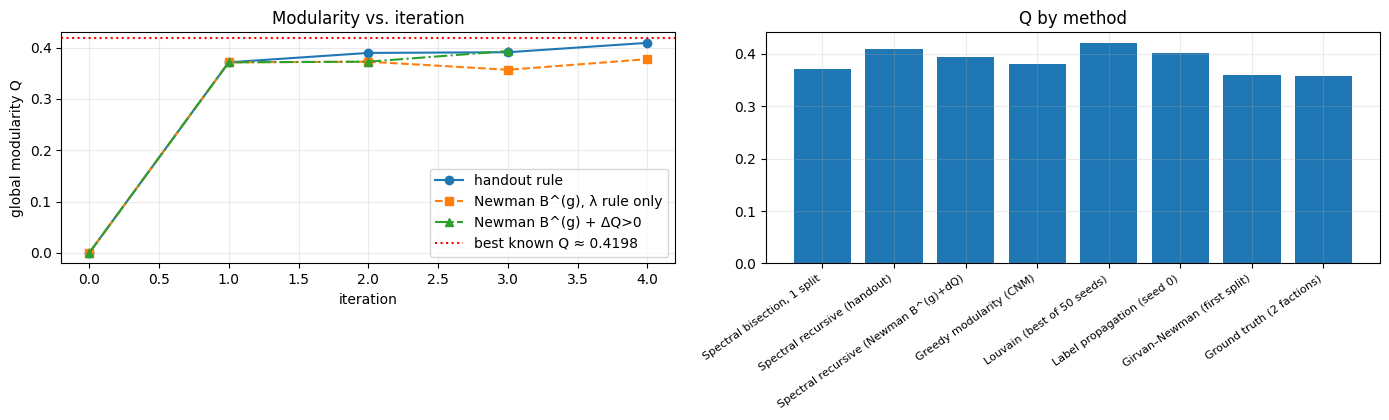

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
axes[0].plot([h["step"] for h in H], [h["Q"] for h in H], "o-", label="handout rule")
axes[0].plot([h["step"] for h in H_nl], [h["Q"] for h in H_nl], "s--", label="Newman B^(g), λ rule only")
axes[0].plot([h["step"] for h in H_new], [h["Q"] for h in H_new], "^-.", label="Newman B^(g) + ΔQ>0")
axes[0].axhline(0.4198, color="r", ls=":", label="best known Q ≈ 0.4198")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("global modularity Q"); axes[0].legend(); axes[0].set_title("Modularity vs. iteration")
axes[1].bar(range(len(cmp_df)), cmp_df["Q"]); axes[1].set_xticks(range(len(cmp_df)))
axes[1].set_xticklabels(cmp_df["method"], rotation=35, ha="right", fontsize=8); axes[1].set_title("Q by method")
plt.tight_layout(); plt.show()

### 6.4 Robustness: how stable is the split under edge noise?
We delete a random fraction of the edges, redo the first spectral split 300 times, and measure (a) how often each node lands on the same side as in the unperturbed graph and (b) agreement with the true factions.

                   remove 5% edges  remove 10% edges  remove 20% edges  remove 30% edges
mean ARI vs truth            0.871             0.838             0.783             0.674
median ARI                   0.882             0.882             0.772             0.668
min ARI                      0.668             0.572             0.326             0.198
P(ARI>0.85)                  0.830             0.607             0.413             0.170


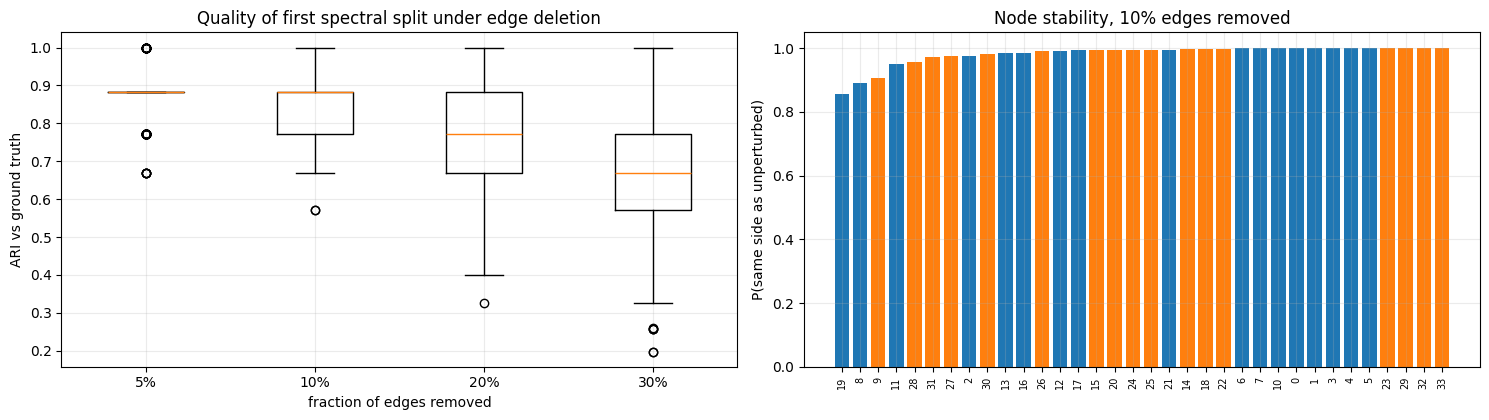

Least stable nodes (10% removal): {19: 0.857, 8: 0.89, 9: 0.907, 11: 0.95, 28: 0.957, 31: 0.973}


In [ ]:
def first_split(Gx):
    Bx, *_ = modularity_matrix(Gx)
    w, V = np.linalg.eigh(Bx)
    return np.where(V[:, -1] > 0, 1, 0), w[-1]

base, _ = first_split(G)
edges = list(G.edges())
def perturb_experiment(frac, trials=300):
    agree = np.zeros(n); aris = []
    for _ in range(trials):
        keep = RNG.random(len(edges)) > frac
        Gx = nx.Graph(); Gx.add_nodes_from(range(n)); Gx.add_edges_from([e for e, kp in zip(edges, keep) if kp])
        lab, _ = first_split(Gx)
        if (lab == base).mean() < .5: lab = 1 - lab
        agree += (lab == base); aris.append(ARI(truth, lab))
    return agree / trials, np.array(aris)

fracs = [0.05, 0.10, 0.20, 0.30]
rob = {f: perturb_experiment(f) for f in fracs}
print(pd.DataFrame({f"remove {int(f*100)}% edges": [rob[f][1].mean(), np.median(rob[f][1]), rob[f][1].min(), (rob[f][1] > .85).mean()] for f in fracs},
                   index=["mean ARI vs truth", "median ARI", "min ARI", "P(ARI>0.85)"]).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].boxplot([rob[f][1] for f in fracs]); axes[0].set_xticklabels([f"{int(f*100)}%" for f in fracs]); axes[0].set_xlabel("fraction of edges removed"); axes[0].set_ylabel("ARI vs ground truth")
axes[0].set_title("Quality of first spectral split under edge deletion")
st = rob[0.10][0]; order = np.argsort(st)
axes[1].bar(range(n), st[order], color=[("C0" if truth[i] == 0 else "C1") for i in order]); axes[1].set_xticks(range(n)); axes[1].set_xticklabels(order, fontsize=7, rotation=90)
axes[1].set_ylabel("P(same side as unperturbed)"); axes[1].set_title("Node stability, 10% edges removed"); plt.tight_layout(); plt.show()
print("Least stable nodes (10% removal):", {int(i): round(float(st[i]), 3) for i in np.argsort(st)[:6]})

### 6.5 Is $Q\approx0.4$ surprising? A degree-matched random-graph null model
We generate 500 random graphs with exactly the karate club's degree sequence (configuration model, simplified), run the same recursive algorithm, and compare the modularity they reach.

Null model: Q = 0.308 ± 0.033 (max 0.421);  mean #communities = 6.12
Observed Q = 0.4094;  z = 3.11;  empirical p = 0.0060


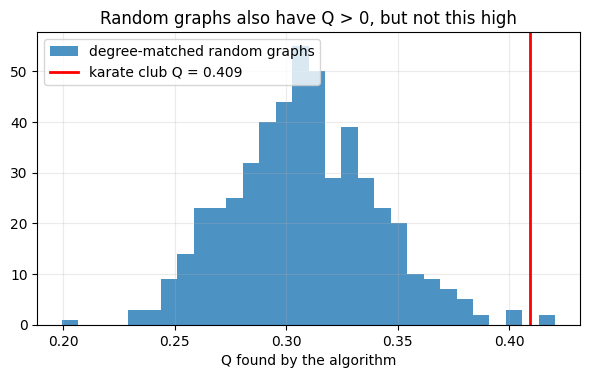

In [ ]:
deg_seq = [d for _, d in G.degree()]
null_Q, null_nc = [], []
for s in range(500):
    Gr = nx.Graph(nx.configuration_model(deg_seq, seed=s)); Gr.remove_edges_from(nx.selfloop_edges(Gr))
    Gr = nx.convert_node_labels_to_integers(Gr)
    Hr, _ = spectral_modularity_partition(Gr, "assignment")
    null_Q.append(Hr[-1]["Q"]); null_nc.append(len(np.unique(Hr[-1]["labels"])))
null_Q = np.array(null_Q); Qobs = H[-1]["Q"]
z = (Qobs - null_Q.mean()) / null_Q.std(); pval = (np.sum(null_Q >= Qobs) + 1) / (len(null_Q) + 1)
print(f"Null model: Q = {null_Q.mean():.3f} ± {null_Q.std():.3f} (max {null_Q.max():.3f});  mean #communities = {np.mean(null_nc):.2f}")
print(f"Observed Q = {Qobs:.4f};  z = {z:.2f};  empirical p = {pval:.4f}")
plt.figure(figsize=(7, 3.8)); plt.hist(null_Q, bins=30, color="C0", alpha=.8, label="degree-matched random graphs")
plt.axvline(Qobs, color="r", lw=2, label=f"karate club Q = {Qobs:.3f}"); plt.xlabel("Q found by the algorithm"); plt.legend(); plt.title("Random graphs also have Q > 0, but not this high"); plt.show()

### 6.6 Phase transition on synthetic two-block graphs (planted partition)
Two blocks of 50 nodes with $p_{in}=0.15$ and increasing $p_{out}$. This tests *when* the spectral method can recover a planted split, which is the benchmark the karate club cannot give us because it has a single instance.

 p_out  ARI_spectral    sd  lambda1
 0.010         0.987 0.024    7.842
 0.024         0.956 0.039    7.357
 0.039         0.823 0.099    6.962
 0.053         0.606 0.123    6.495
 0.068         0.319 0.183    6.320
 0.082         0.123 0.120    6.185
 0.097         0.041 0.064    6.176
 0.111         0.014 0.029    6.341
 0.126         0.000 0.014    6.452
 0.140        -0.003 0.009    6.594


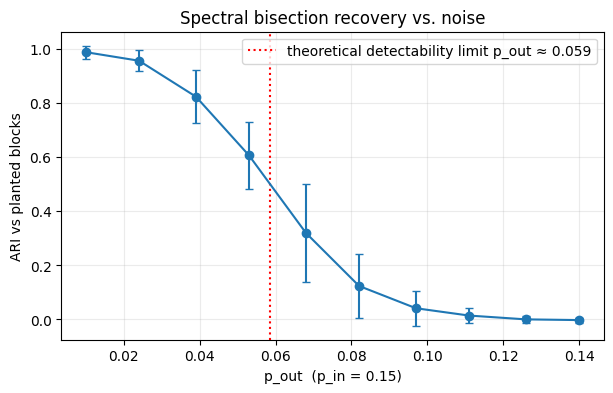

Theoretical detectability threshold: p_out ≈ 0.059


In [ ]:
p_in = 0.15; p_outs = np.round(np.linspace(0.01, 0.14, 10), 3); trials = 25
rows = []
sizes = [50, 50]; planted = np.repeat([0, 1], 50)
for po in p_outs:
    a_sp, lam1 = [], []
    for s in range(trials):
        Gs = nx.stochastic_block_model(sizes, [[p_in, po], [po, p_in]], seed=1000 * s + int(po * 1000))
        lab, l1 = first_split(Gs); a_sp.append(ARI(planted, lab)); lam1.append(l1)
    rows.append(dict(p_out=po, ARI_spectral=np.mean(a_sp), sd=np.std(a_sp), lambda1=np.mean(lam1)))
sbm = pd.DataFrame(rows)
print(sbm.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(sbm.p_out, sbm.ARI_spectral, sbm.sd, marker="o", capsize=3); ax.set_xlabel("p_out  (p_in = 0.15)"); ax.set_ylabel("ARI vs planted blocks")
a_ = p_in * 50; thr = ((a_ + 1) - np.sqrt(4 * a_ + 1)) / 50      # Kesten–Stigum / detectability: (c_in-c_out)^2 = 2(c_in+c_out)
ax.axvline(thr, color="r", ls=":", label=f"theoretical detectability limit p_out ≈ {thr:.3f}"); ax.legend()
ax.set_title("Spectral bisection recovery vs. noise"); plt.show()
print(f"Theoretical detectability threshold: p_out ≈ {thr:.3f}")

### 6.7 Benchmark across other networks
Same algorithm (both variants) on several other graphs bundled with `networkx`, compared with Louvain, plus the null-model $z$-score for each.

In [ ]:
def to_simple_int(Gx):
    Gx = nx.Graph(Gx); Gx.remove_edges_from(nx.selfloop_edges(Gx))
    Gx = Gx.subgraph(max(nx.connected_components(Gx), key=len)).copy()
    return nx.convert_node_labels_to_integers(Gx)

women = [v for v, d in nx.davis_southern_women_graph().nodes(data=True) if d["bipartite"] == 0]
nets = {
    "Karate club": G,
    "Les Misérables": to_simple_int(nx.les_miserables_graph()),
    "Davis southern women (projection)": to_simple_int(nx.bipartite.projected_graph(nx.davis_southern_women_graph(), women)),
    "Florentine families": to_simple_int(nx.florentine_families_graph()),
    "Connected caveman (6 x 8)": nx.connected_caveman_graph(6, 8),
    "Barabási–Albert (n=100, m=3)": nx.barabasi_albert_graph(100, 3, seed=1),
    "Erdős–Rényi (n=100, p=.06)": to_simple_int(nx.gnp_random_graph(100, .06, seed=1)),
}
rows = []
for name, Gx in nets.items():
    Ha, _ = spectral_modularity_partition(Gx, "assignment"); Hn, _ = spectral_modularity_partition(Gx, "newman+dq")
    lv = max((nx.community.modularity(Gx, nx.community.louvain_communities(Gx, seed=s)) for s in range(20)))
    dseq = [d for _, d in Gx.degree()]; nq = []
    for s in range(60):
        Gr = nx.Graph(nx.configuration_model(dseq, seed=s)); Gr.remove_edges_from(nx.selfloop_edges(Gr)); Gr = nx.convert_node_labels_to_integers(Gr)
        nq.append(spectral_modularity_partition(Gr, "newman+dq")[0][-1]["Q"])
    rows.append(dict(network=name, n=Gx.number_of_nodes(), m=Gx.number_of_edges(),
                     comms_handout=len(np.unique(Ha[-1]["labels"])), Q_handout=Ha[-1]["Q"],
                     comms_newman=len(np.unique(Hn[-1]["labels"])), Q_newman=Hn[-1]["Q"], Q_louvain=lv,
                     z_vs_null=(Hn[-1]["Q"] - np.mean(nq)) / np.std(nq)))
bench = pd.DataFrame(rows); print(bench.round(3).to_string(index=False))

                          network   n   m  comms_handout  Q_handout  comms_newman  Q_newman  Q_louvain  z_vs_null
                      Karate club  34  78              5      0.409             4     0.393      0.420      2.439
                   Les Misérables  77 254              9      0.531             9     0.540      0.567     14.331
Davis southern women (projection)  18 139              2      0.013             2     0.013      0.018     -4.231
              Florentine families  15  20              3      0.364             3     0.364      0.399     -0.688
        Connected caveman (6 x 8)  48 168              8      0.738             6     0.724      0.798     19.115
     Barabási–Albert (n=100, m=3) 100 291             12      0.266             7     0.285      0.353     -1.265
       Erdős–Rényi (n=100, p=.06) 100 313             14      0.301             6     0.314      0.370     -0.253


### 6.8 Do node roles line up with community boundaries?
For the final partition we measure each node's fraction of edges leaving its community and compare with its original (iteration-0) betweenness and with how much betweenness and degree centrality it *loses* once cross-community edges are removed.

Nodes with edges leaving their community (sorted by betweenness):
    external_edge_frac  betweenness_0  betweenness_lost  degree_lost
0                0.438          0.438             0.413        0.212
33               0.294          0.304             0.236        0.152
32               0.167          0.145             0.113        0.061
2                0.500          0.144             0.143        0.152
31               0.500          0.138             0.133        0.091
8                0.400          0.056             0.056        0.061
1                0.111          0.054             0.039        0.030
13               0.200          0.046             0.046        0.030
19               0.333          0.032             0.032        0.030
5                0.250          0.030             0.027        0.030
6                0.250          0.030             0.027        0.030
27               0.750          0.022             0.022        0.091
23               0.400          0.018

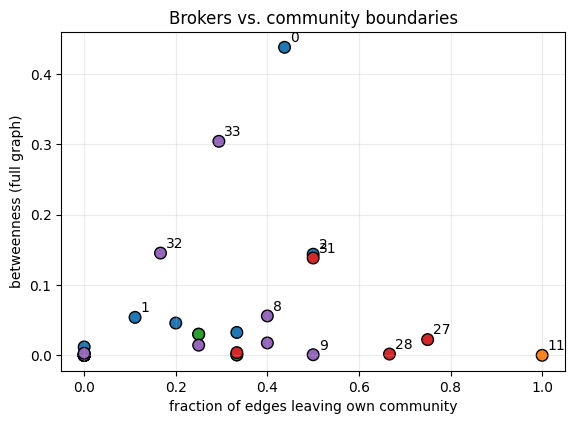

In [ ]:
lab = H[-1]["labels"]
ext = pd.Series({i: sum(lab[j] != lab[i] for j in G[i]) / G.degree(i) for i in G}, name="external_edge_frac")
bet0 = tables["betweenness"][0].rename("betweenness_0")
dbet = (tables["betweenness"][0] - tables["betweenness"][len(H)-1]).rename("betweenness_lost")
ddeg = (tables["degree"][0] - tables["degree"][len(H)-1]).rename("degree_lost")
an = pd.concat([ext, bet0, dbet, ddeg], axis=1)
print("Nodes with edges leaving their community (sorted by betweenness):")
print(an[an.external_edge_frac > 0].sort_values("betweenness_0", ascending=False).round(3).to_string())
print("\nSpearman correlations:"); print(an.corr(method="spearman").round(3).to_string())
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.scatter(an.external_edge_frac, an.betweenness_0, c=[cmap(lab[i] % 10) for i in an.index], s=70, edgecolors="k")
for i in an.index:
    if an.betweenness_0[i] > .05 or an.external_edge_frac[i] > .4: ax.annotate(str(i), (an.external_edge_frac[i], an.betweenness_0[i]), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("fraction of edges leaving own community"); ax.set_ylabel("betweenness (full graph)"); ax.set_title("Brokers vs. community boundaries"); plt.show()

## 7. Discussion

**Does the method find the real split?** Yes, with one famous exception. The first spectral split (16 + 18 nodes, $Q=0.372$, $\lambda_1=4.98$) matches Zachary's two factions for 33 of 34 members (ARI $=0.88$). The only error is node 8, who is recorded as a Mr. Hi follower but has 3 of his 5 friends in the other camp; he is also among the nodes with the smallest $|u_1|$ (closest to the threshold) and among the least stable nodes under edge deletion (6.4). Splitting further raises $Q$ (to 0.409 after four splits) but *lowers* agreement with the two-faction truth (ARI 0.45), because the extra communities are real sub-structure of the friendship graph, not part of the recorded schism. The true two-faction partition itself has only $Q=0.358$, below Louvain's 0.420: maximising modularity and recovering the social split are related but not identical goals.

**Which nodes stay central?** Nodes **33, 32 and 0** are in the top-5 for degree *and* betweenness at all five iterations; node 31 is a near-constant in betweenness/closeness and node 1 in degree. Nodes 0 and 33 are the two faction leaders (Mr. Hi and the officer), so they remain hubs inside whichever community they end up in. Clustering behaves differently: its top-5 is made of low-degree nodes sitting inside cliques (7, 12, 14, …), so the *least* connected members are the most "locally cohesive" and clustering says almost nothing about overall importance.

**How community structure changes the metrics.** Degree is the most stable (Spearman rank correlation with iteration 0 stays 0.84 after four splits) because most of a node's edges are inside its community. Betweenness and closeness are far less stable (0.63 and 0.34): they depend on paths *between* communities, which the splits cut. Node 0's betweenness drops from 0.438 to 0.024 and node 33's from 0.304 to 0.068, i.e. most of their brokerage value came from bridging the two camps. Nodes that lose the most betweenness are those with many edges leaving their community (6.8: Spearman 0.90 between initial betweenness and betweenness lost).

**Caveats found while implementing the handout's rule (worth knowing for the exam).**
1. *The sub-block $B^{(C)}$ is not Newman's generalised matrix.* Without the diagonal correction $B^{(g)}_{ii}\mathrel{-}=\sum_{l\in g}B_{il}$, $\tfrac1{4m}s^\top B^{(C)}s$ does not equal the true $\Delta Q$ (e.g. 0.111 predicted vs 0.018 actual at split 2), and the leading eigenvalue of a block is usually positive and its eigenvector one-signed. The handout's recursion therefore stops through degenerate (one-sided) splits rather than through $\lambda_1\le0$.
2. *$\lambda_1>0$ is necessary, not sufficient.* With the corrected matrix, $\lambda_1=0.06$ still produced a split with $\Delta Q=-0.016$. Checking the exact $\Delta Q>0$ (variant `newman+dq`) is what makes every accepted split improve $Q$.
3. *Theorem 3's direction is right:* $\lambda_1\le0\Rightarrow\Delta Q\le0$. The converse is false, which is exactly point 2.

**Extra evidence.** (6.5) Degree-matched random graphs reach $Q=0.31\pm0.03$ with this algorithm, so a $Q$ of about 0.4 is significantly above chance ($z\approx3.1$, $p\approx0.006$) but a $Q$ of 0.3 alone would not be impressive. (6.4) The split is fairly robust: median ARI stays at 0.88 with 10% of edges removed and degrades gradually. (6.6) On planted two-block graphs, recovery collapses close to the theoretical detectability limit $p_{out}\approx0.059$, as theory predicts, which explains why spectral methods fail on the noisy random and Barabási–Albert graphs in 6.7 (z-scores near zero) yet succeed on Les Misérables and the caveman graph (z > 14).

**References.** Newman, M. E. J. (2006). Modularity and community structure in networks. *PNAS* 103(23), 8577–8582. Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *J. Anthropological Research* 33(4), 452–473.